In [1]:
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense

In [2]:

# Load dataset using less memory
df = pd.read_csv("cifar-10.csv", dtype=np.uint8)

# Separate features and labels
X = df.iloc[:, :-1].to_numpy(dtype=np.uint8)
y = df["label"].to_numpy(dtype=np.int64)

# Reshape images
X = X.reshape(-1, 3, 32, 32)
X = X.transpose(0, 2, 3, 1)

print("Image shape:", X.shape)
print("Label shape:", y.shape)

Image shape: (50000, 32, 32, 3)
Label shape: (50000,)


In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (40000, 32, 32, 3)
Testing data: (10000, 32, 32, 3)


In [4]:
BATCH_SIZE = 32

train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train))

train_ds = (
    train_ds
    .shuffle(5000)
    .batch(BATCH_SIZE)
    .map(lambda x, y: (tf.cast(x, tf.float32) / 255.0, y))
    .prefetch(1)
)

test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test))

test_ds = (
    test_ds
    .batch(BATCH_SIZE)
    .map(lambda x, y: (tf.cast(x, tf.float32) / 255.0, y))
    .prefetch(1)
)

In [5]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense



model = tf.keras.Sequential([

    tf.keras.layers.Input(shape=(32, 32, 3)),

    # First Convolutional Layer
    tf.keras.layers.Conv2D(
        32, (3, 3), activation='relu'
    ),

    # First Max Pooling Layer
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Second Convolutional Layer
    tf.keras.layers.Conv2D(
        64, (3, 3), activation='relu'
    ),

    # Second Max Pooling Layer
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Flatten Layer
    tf.keras.layers.Flatten(),

    # Fully Connected Layer
    tf.keras.layers.Dense(128, activation='relu'),

    # Output Layer
    tf.keras.layers.Dense(24, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 30, 30, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 15, 15, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 13, 13, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 6, 6, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 2304)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         295,040 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 24)                  │           3,096 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 317,528 (1.21 MB)

 Trainable params: 317,528 (1.21 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
history = model.fit(
    train_ds,
    epochs=10,
    validation_data=test_ds
)

Epoch 1/10


C:\Users\saniya maner\miniconda3\envs\tensorflow_env\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1250/1250 ━━━━━━━━━━━━━━━━━━━━ 13s 9ms/step - accuracy: 0.4495 - loss: 1.5275 - val_accuracy: 0.5630 - val_loss: 1.2682
Epoch 2/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - accuracy: 0.5940 - loss: 1.1472 - val_accuracy: 0.6073 - val_loss: 1.1153
Epoch 3/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - accuracy: 0.6515 - loss: 0.9967 - val_accuracy: 0.6606 - val_loss: 0.9873
Epoch 4/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 12s 10ms/step - accuracy: 0.6879 - loss: 0.8993 - val_accuracy: 0.6701 - val_loss: 0.9584
Epoch 5/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - accuracy: 0.7137 - loss: 0.8170 - val_accuracy: 0.6584 - val_loss: 0.9940
Epoch 6/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - accuracy: 0.7395 - loss: 0.7480 - val_accuracy: 0.6804 - val_loss: 0.9574
Epoch 7/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - accuracy: 0.7653 - loss: 0.6765 - val_accuracy: 0.6773 - val_loss: 0.9657
Epoch 8/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - accuracy: 0.7850 - loss: 0.6146 - v

In [7]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.6847 - loss: 1.0611
Test Accuracy: 0.6847000122070312
Test Loss: 1.0611448287963867


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step


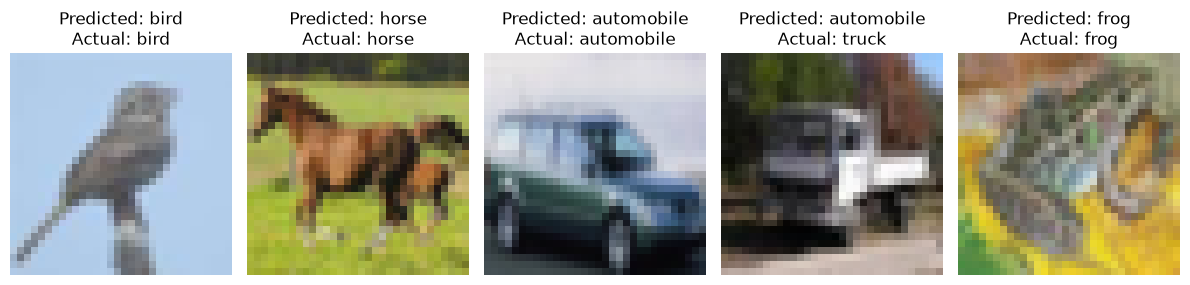

In [8]:
import numpy as np
import matplotlib.pyplot as plt

class_names = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]

# Get predictions for first 5 test images
predictions = model.predict(test_ds.take(1))

# Get predicted labels
predicted_labels = np.argmax(predictions, axis=1)

# Display first 5 test images
plt.figure(figsize=(12, 5))

for i in range(5):
    plt.subplot(1, 5, i + 1)

    plt.imshow(X_test[i])

    plt.title(
        "Predicted: " + class_names[predicted_labels[i]] +
        "\nActual: " + class_names[y_test[i]]
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
# Build a CNN model for object classification. Evaluate its performance
# using test images and generate a confusion matrix. Use Dataset -
# CIFAR-10